# 02 · ARIMAX, Granger causality, forecasting and VAR

**Question:** once we know elk follow a random walk with drift (notebook 01), do wolves, bison, vegetation, climate or hunting explain the year-to-year changes?

**Target:** y_t = Δ log(elk)_t = log E_t − log E_{t−1} (≈ % change in elk from one winter count to the next).
Notebook 01 showed y_t is white noise, so the ARIMAX is

  y_t = μ + β₁x₁ + … + β_k x_k + ε_t,  ε_t white noise

i.e. an **ARIMAX(0,1,0)** on log elk. (Sensitivity check: MA(2) errors, the close alternative from notebook 01.)

Sections
1. Data and time alignment
2. Making every regressor stationary
3. One variable at a time (screening)
4. Granger causality tests
5. The full ARIMAX model + diagnostics (residual ACF, Ljung–Box, ARCH)
6. Reduced model (wolves only) and robustness checks
7. Rolling-origin forecast evaluation (2011–2025)
8. VAR: elk and wolves as a two-way system
9. Summary

In [1]:
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / "data" / "processed" / "yellowstone_master_ts_flagged.csv", index_col="Year")
harv = pd.read_csv(ROOT / "data" / "raw" / "elk_harvest_northern.csv", index_col="Year")
df = df.join(harv[["Harvest_Total", "Harvest_source", "Harvest_imputed"]])
df[["Elk_Count", "Wolf_Northern", "Bison_Count", "NDVI", "Precip_Annual", "PDSI_Annual", "Harvest_Total"]].tail()

,Elk_Count,Wolf_Northern,Bison_Count,NDVI,Precip_Annual,PDSI_Annual,Harvest_Total
Year,,,,,,,
2021,4609.0,55,3830,0.5194,525.0396,-2.0878,367
2022,5473.0,60,4507,0.5796,578.8747,0.0141,318
2023,5142.0,69,4507,0.5939,603.1698,0.9545,335
2024,4789.0,57,4550,0.5547,521.7272,-2.0755,289
2025,6124.0,53,5300,0.5136,521.7272,-2.0755,346


## 1. Time alignment

Each elk count is a winter count: the value labelled year *t* is flown in Dec (t−1) – Jan (t).
So y_t is the change over the **12 months before** count *t*. Every regressor is aligned to that same window:

| Variable | Measured when | Use in row *t* |
|---|---|---|
| Wolves (northern range) | December count | year t−1 (wolves present during the 12 months) |
| Bison (northern herd) | summer count | year t−1 |
| Summer NDVI | Jun–Aug | year t−1 (summer forage before the winter count) |
| Precipitation, PDSI | calendar year | year t−1 |
| Harvest | hunting season (t−1)–t, labelled by the winter it ends | year t (fall hunt Oct–Nov t−1 and late hunt Dec–Feb, i.e. before/around count t) |

So all regressors are "last 12 months" information. The harvest file is already labelled by winter-end year, which is why it is *not* shifted.

In [2]:
Y = np.log(df["Elk_Count"]).diff().rename("dlog_elk")
raw = pd.DataFrame({
    "wolves":   df["Wolf_Northern"].shift(1),
    "bison":    df["Bison_Count"].shift(1),
    "ndvi":     df["NDVI"].shift(1),
    "precip":   df["Precip_Annual"].shift(1),
    "pdsi":     df["PDSI_Annual"].shift(1),
    "harvest_rate": df["Harvest_Total"] / df["Elk_Count"].shift(1),   # share of last winter's herd removed
})
raw.loc[1990:2000].round(3)

,wolves,bison,ndvi,precip,pdsi,harvest_rate
Year,,,,,,
1990,0.0,432.0,0.464,604.584,-1.760,0.077
1991,0.0,818.0,0.476,486.002,-1.836,0.068
1992,0.0,822.0,0.498,602.013,0.378,0.326
1993,0.0,681.0,0.496,583.997,-0.683,0.160
1994,0.0,636.0,0.512,601.566,2.126,0.030
1995,0.0,1140.0,0.472,571.140,-2.536,0.133
1996,21.0,866.0,0.543,686.753,2.664,0.102
1997,30.0,860.0,0.496,672.077,1.519,0.220
1998,40.0,455.0,0.568,696.162,3.531,0.124


## 2. Make every regressor stationary

Same rule as notebook 01: ADF at lags 0, 1, 2 (stationary if it rejects at ≥ 2 of 3) plus KPSS. Non-stationary regressors are differenced. Regressing a stationary y on a trending x is how spurious results happen.

Harvest is entered as a **rate** (harvest ÷ previous elk count): removing 1,000 elk matters far more from a herd of 5,000 than from 19,000, and log-growth responds to the fraction removed.

In [3]:
def stationarity(x):
    x = x.dropna()
    ps = [adfuller(x, maxlag=l, autolag=None)[1] for l in (0, 1, 2)]
    adf = sum(p < 0.05 for p in ps) >= 2
    k = kpss(x, regression="c", nlags="auto")[1] < 0.05
    verdict = "stationary" if adf and not k else "non-stationary" if (not adf and k) else "inconclusive"
    return dict(ADF_p_lag0=ps[0], ADF_p_lag1=ps[1], ADF_p_lag2=ps[2], KPSS_rejects=k, verdict=verdict)

st = pd.DataFrame({c: stationarity(raw[c]) for c in raw}).T
st

,ADF_p_lag0,ADF_p_lag1,ADF_p_lag2,KPSS_rejects,verdict
wolves,0.438058,0.394571,0.562267,True,non-stationary
bison,0.974598,0.9908,0.990121,True,non-stationary
ndvi,0.005099,0.045301,0.187685,False,stationary
precip,0.000104,0.009125,0.167555,False,stationary
pdsi,0.000778,0.039152,0.05345,False,stationary
harvest_rate,0.000107,0.024521,0.315744,True,inconclusive


In [4]:
# Transform: difference anything not clearly stationary (wolves, bison), keep the rest in levels.
X = pd.DataFrame({
    "d_wolves": raw["wolves"].diff() / 10,          # change in wolves, per 10 wolves
    "d_logbison": np.log(raw["bison"]).diff(),      # % change in bison
    "ndvi": (raw["ndvi"] - raw["ndvi"].mean()) / raw["ndvi"].std(),        # standardised (1 = 1 SD)
    "precip": (raw["precip"] - raw["precip"].mean()) / raw["precip"].std(),
    "pdsi": (raw["pdsi"] - raw["pdsi"].mean()) / raw["pdsi"].std(),
    "harvest_rate": raw["harvest_rate"] * 10,       # per 10 percentage points of the herd
})
st2 = pd.DataFrame({c: stationarity(X[c]) for c in X}).T
st2[["verdict"]]

,verdict
d_wolves,stationary
d_logbison,stationary
ndvi,stationary
precip,stationary
pdsi,stationary
harvest_rate,inconclusive


Units for reading coefficients (β × 100 ≈ % change in elk per year):
- `d_wolves`: +10 wolves on the northern range compared with the year before
- `d_logbison`: bison grew 100 % (so β/10 ≈ effect of 10 % bison growth)
- `ndvi`, `precip`, `pdsi`: one standard deviation above average
- `harvest_rate`: 10 % of the herd removed

## 3. One variable at a time

Each regressor alone: y_t = μ + βx_t + ε_t. This is a screen, not the final answer. With 6 tests at the 5 % level, about 0.3 false positives are expected by chance, so a p-value near 0.05 is weak evidence on its own.

In [5]:
def fit_arimax(y, X=None, order=(0, 0, 0)):
    d = pd.concat([y, X], axis=1).dropna() if X is not None else y.dropna().to_frame()
    exog = d.drop(columns=y.name) if X is not None else None
    return ARIMA(d[y.name], exog=exog, order=order, trend="c").fit(), d

rows = []
for c in X:
    res, d = fit_arimax(Y, X[[c]])
    rows.append(dict(variable=c, beta=res.params[c], pct_effect=100 * res.params[c],
                     p=res.pvalues[c], n=len(d), years=f"{d.index.min()}–{d.index.max()}"))
screen = pd.DataFrame(rows).set_index("variable")
screen.round(3)

,beta,pct_effect,p,n,years
variable,,,,,
d_wolves,-0.040,-3.957,0.042,40,1986–2025
d_logbison,-0.047,-4.676,0.638,40,1986–2025
ndvi,0.018,1.785,0.591,41,1985–2025
precip,0.014,1.366,0.644,41,1985–2025
pdsi,0.005,0.472,0.871,41,1985–2025
harvest_rate,-0.023,-2.323,0.707,41,1985–2025


## 4. Granger causality

"x Granger-causes elk" means: past values of x improve the prediction of elk changes beyond what past elk changes already give. It tests prediction, not biological cause. Lags 1 and 2 are tested; the F-test p-value is reported.

Note the regressors in `X` are already aligned to the 12 months before each count, so "lag 1" here means the window directly before the count.

In [6]:
g = []
for c in X:
    d = pd.concat([Y, X[c].shift(-1)], axis=1).dropna()   # undo the alignment shift; grangercausalitytests adds its own lags
    out = grangercausalitytests(d[["dlog_elk", c]], maxlag=2)
    g.append({"variable": c, "p (lag 1)": out[1][0]["ssr_ftest"][1], "p (lags 1–2)": out[2][0]["ssr_ftest"][1]})
granger = pd.DataFrame(g).set_index("variable")
granger.round(3)

,p (lag 1),p (lags 1–2)
variable,,
d_wolves,0.049,0.082
d_logbison,0.594,0.840
ndvi,0.669,0.491
precip,0.424,0.653
pdsi,0.703,0.693
harvest_rate,0.636,0.072


## 5. Full ARIMAX model

All six regressors at once, white-noise errors (the chosen model from notebook 01). Then the same model with MA(2) errors as a sensitivity check.

In [7]:
full, dfull = fit_arimax(Y, X)
print(full.summary().tables[1])
print(f"n = {len(dfull)} ({dfull.index.min()}–{dfull.index.max()})")
base, _ = fit_arimax(Y.loc[dfull.index])
print(f"Residual variance: drift only {base.params['sigma2']:.4f}  ->  full ARIMAX {full.params['sigma2']:.4f}"
      f"  ({100*(1-full.params['sigma2']/base.params['sigma2']):.0f}% explained)")

                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.0154      0.060     -0.256      0.798      -0.134       0.103
d_wolves        -0.0412      0.027     -1.537      0.124      -0.094       0.011
d_logbison      -0.0481      0.102     -0.471      0.638      -0.248       0.152
ndvi             0.0210      0.036      0.587      0.557      -0.049       0.091
precip           0.0113      0.052      0.218      0.828      -0.090       0.113
pdsi            -0.0083      0.055     -0.151      0.880      -0.117       0.100
harvest_rate    -0.0013      0.064     -0.021      0.983      -0.127       0.125
sigma2           0.0179      0.005      3.300      0.001       0.007       0.029
n = 40 (1986–2025)
Residual variance: drift only 0.0214  ->  full ARIMAX 0.0179  (16% explained)


In [8]:
full_ma2, _ = fit_arimax(Y, X, order=(0, 0, 2))
comp = pd.DataFrame({"white-noise errors: β": full.params, "p": full.pvalues,
                     "MA(2) errors: β": full_ma2.params, "p ": full_ma2.pvalues}).drop(["sigma2"])
comp.round(3)

,white-noise errors: β,p,MA(2) errors: β,p
const,-0.015,0.798,-0.043,0.464
d_logbison,-0.048,0.638,0.000,0.996
d_wolves,-0.041,0.124,-0.041,0.039
harvest_rate,-0.001,0.983,0.026,0.681
ma.L1,NaN,NaN,0.324,0.779
ma.L2,NaN,NaN,-0.662,0.392
ndvi,0.021,0.557,0.032,0.472
pdsi,-0.008,0.880,0.013,0.798
precip,0.011,0.828,-0.014,0.733


### Diagnostics
The residuals should be white noise (residual ACF inside the bands, Ljung–Box p > 0.05) with constant variance (ARCH test p > 0.05; if it failed, a GARCH model would be needed).

full ARIMAX: Ljung–Box p (lag 5, 8) = 0.49, 0.72;  ARCH test p = 0.17


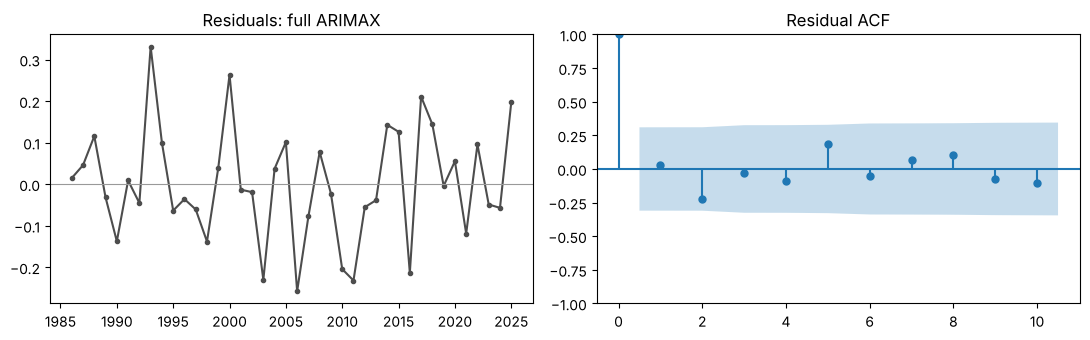

In [9]:
def diagnose(res, name, fname=None):
    r = res.resid
    lb = acorr_ljungbox(r, lags=[5, 8]).lb_pvalue.values
    arch_p = het_arch(r, nlags=2)[1]
    print(f"{name}: Ljung–Box p (lag 5, 8) = {lb[0]:.2f}, {lb[1]:.2f};  ARCH test p = {arch_p:.2f}")
    if fname:
        fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
        ax[0].plot(r.index, r, "o-", ms=3, color="0.3"); ax[0].axhline(0, color="0.6", lw=0.8)
        ax[0].set_title(f"Residuals: {name}")
        plot_acf(r, lags=10, ax=ax[1]); ax[1].set_title("Residual ACF")
        fig.tight_layout(); fig.savefig(FIG / fname, dpi=200)

diagnose(full, "full ARIMAX", "08_arimax_residuals.png")

## 6. Reduced model and robustness

In the full model nothing is significant: six regressors on 40 years spreads the evidence thin. The reduced model keeps the regressors that passed the one-at-a-time screen (p < 0.05 in section 3), refits, then checks whether the result survives:
- **(a) real counts only:** drop every year where this count or the previous one was imputed;
- **(b) before the 2016 splice:** drop 2016+ (different survey, MT FWP HD 313);
- **(c) wolves in levels** instead of changes (the "predation pressure" view used in the ecology literature);
- **(d) MA(2) errors.**

In [10]:
keep = [c for c in X if screen.loc[c, "p"] < 0.05]
print("Kept:", keep)
red, dred = fit_arimax(Y, X[keep])
print(red.summary().tables[1])
diagnose(red, "reduced ARIMAX")

Kept: ['d_wolves']
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0188      0.023     -0.809      0.418      -0.064       0.027
d_wolves      -0.0396      0.019     -2.029      0.042      -0.078      -0.001
sigma2         0.0187      0.005      3.914      0.000       0.009       0.028
reduced ARIMAX: Ljung–Box p (lag 5, 8) = 0.51, 0.79;  ARCH test p = 0.17


In [11]:
imp = df["Elk_Count_imputed"]
real = (imp == 0) & (imp.shift(1) == 0)
checks = {}
checks["reduced (all years)"] = red
checks["(a) real counts only"], _ = fit_arimax(Y[real], X[keep])
checks["(b) up to 2015"], _ = fit_arimax(Y.loc[:2015], X[keep])
if "d_wolves" in keep:
    Xc = X[keep].drop(columns="d_wolves").assign(wolves_level=raw["wolves"] / 10)
    checks["(c) wolves in levels"], _ = fit_arimax(Y, Xc)
checks["(d) MA(2) errors"], _ = fit_arimax(Y, X[keep], order=(0, 0, 2))
rob = pd.DataFrame({k: pd.concat([v.params.drop(["const", "sigma2"]).filter(regex="^(?!ma)"),
                                  v.pvalues.drop(["const", "sigma2"]).filter(regex="^(?!ma)").add_prefix("p_")])
                    for k, v in checks.items()}).T
rob["n"] = [int(v.nobs) for v in checks.values()]
rob.round(3)

,d_wolves,p_d_wolves,p_wolves_level,wolves_level,n
reduced (all years),-0.040,0.042,NaN,NaN,40
(a) real counts only,-0.050,0.179,NaN,NaN,25
(b) up to 2015,-0.016,0.473,NaN,NaN,30
(c) wolves in levels,NaN,NaN,0.358,-0.008,41
(d) MA(2) errors,-0.034,0.019,NaN,NaN,40


**Reading the table (results on the October 2026 data, before the to-do fixes):**
the wolf effect is about −4 % elk per +10 wolves and survives MA(2) errors, but it is **not robust**:
on real counts only it keeps the same sign but loses significance (n = 25), and before 2016 it almost vanishes (−1.6 %, p ≈ 0.47).
So most of the evidence comes from 2016–2025, which is exactly the part of the elk series spliced in from the MT FWP HD 313 survey.
Fixing that splice is the most important data task before these numbers are final.

## 7. Rolling-origin forecast evaluation (2011–2025)

For each test year *t*: fit on all years before *t*, forecast the count at *t* from the count at *t−1*, compare with the actual count.
Only **real** counts are scored (imputed targets 2014, 2019, 2020 are skipped).

Models: **naive** (next year = this year), **drift** (random walk with drift — the notebook 01 model), **reduced ARIMAX**, **full ARIMAX**.
Note: harvest for winter *t* is set before the count, so it is known at forecast time; the other regressors are all from year *t−1*.

In [12]:
E = df["Elk_Count"]
specs = {"naive": None, "drift": [], "reduced ARIMAX": keep, "full ARIMAX": list(X.columns)}
out = []
for t in range(2011, 2026):
    if imp.loc[t] == 1:
        continue
    row = {"year": t, "actual": E.loc[t]}
    for name, cols in specs.items():
        if cols is None:
            yhat = 0.0
        else:
            train = Y.loc[:t - 1]
            if cols:
                res, _ = fit_arimax(train, X.loc[:t - 1, cols])
                yhat = res.params["const"] + (X.loc[t, cols] * res.params[cols]).sum()
            else:
                yhat = train.dropna().mean()
        row[name] = E.loc[t - 1] * np.exp(yhat)
    out.append(row)
fc = pd.DataFrame(out).set_index("year")
mae = {m: (fc[m] - fc["actual"]).abs().mean() for m in specs}
mape = {m: 100 * ((fc[m] - fc["actual"]).abs() / fc["actual"]).mean() for m in specs}
score = pd.DataFrame({"MAE (elk)": mae, "MAPE (%)": mape}).round(1)
print(f"{len(fc)} test years scored"); score

12 test years scored


,MAE (elk),MAPE (%)
naive,798.5,16.5
drift,760.1,15.3
reduced ARIMAX,661.4,13.4
full ARIMAX,778.6,16.2


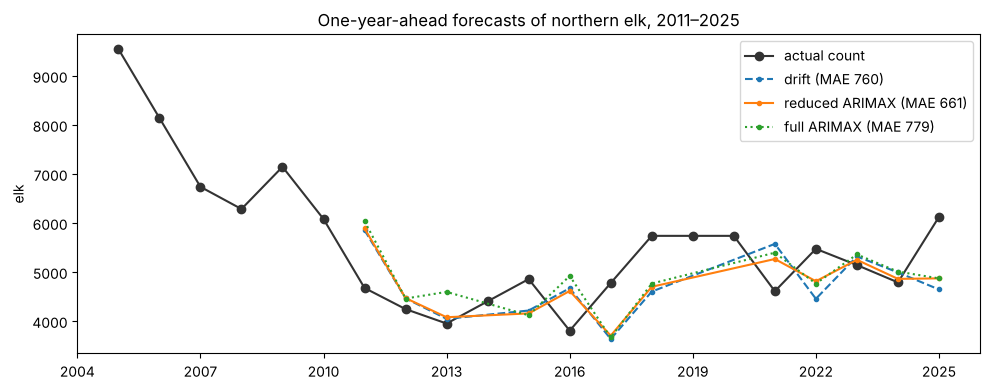

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(E.loc[2005:].index, E.loc[2005:], "o-", color="0.2", label="actual count")
for m, s in zip(["drift", "reduced ARIMAX", "full ARIMAX"], ["--", "-", ":"]):
    ax.plot(fc.index, fc[m], s, marker=".", label=f"{m} (MAE {mae[m]:.0f})")
ax.set_title("One-year-ahead forecasts of northern elk, 2011–2025"); ax.set_ylabel("elk"); ax.legend()
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
fig.tight_layout(); fig.savefig(FIG / "09_rolling_forecasts.png", dpi=200)

## 8. VAR: elk and wolves as a two-way system

ARIMAX assumes wolves affect elk but not the other way round. In reality wolves also depend on elk (their prey). A VAR treats both as outcomes:

  Δlog elk_t = a₁ + b₁₁ Δlog elk_{t−1} + b₁₂ Δwolves_{t−1} + e₁
  Δwolves_t  = a₂ + b₂₁ Δlog elk_{t−1} + b₂₂ Δwolves_{t−1} + e₂

Fitted on 1996–2025 (wolves exist), lag 1 only because the sample is short.

In [14]:
w = df["Wolf_Northern"]
V = pd.DataFrame({"dlog_elk": Y, "d_wolves": w.diff() / 10}).loc[1997:].dropna()
var = VAR(V).fit(1)
print(var.summary())
for caused, causing in [("dlog_elk", "d_wolves"), ("d_wolves", "dlog_elk")]:
    t = var.test_causality(caused, [causing], kind="f")
    print(f"{causing} Granger-causes {caused}: p = {t.pvalue:.3f}")

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Thu, 15, Oct, 2026
Time:                     07:46:22
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                   -2.49602
Nobs:                     28.0000    HQIC:                  -2.69422
Log likelihood:          -34.5197    FPE:                  0.0620486
AIC:                     -2.78149    Det(Omega_mle):       0.0506203
--------------------------------------------------------------------
Results for equation dlog_elk
                 coefficient       std. error           t-stat            prob
------------------------------------------------------------------------------
const              -0.026213         0.029547           -0.887           0.375
L1.dlog_elk        -0.045827         0.196348           -0.233           0.815
L1.d_wolves        -0.038594         0.018819           -2.051   

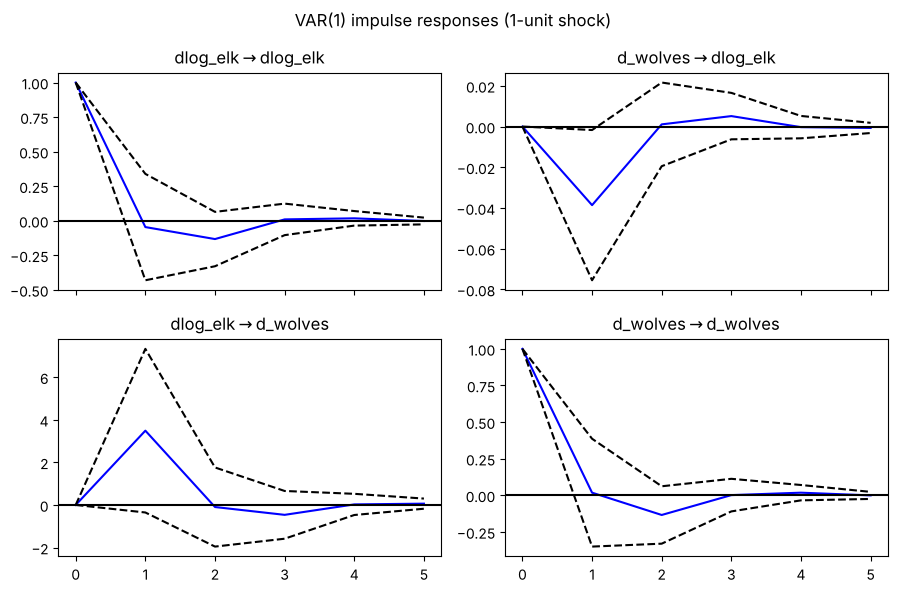

In [15]:
irf = var.irf(5)
fig = irf.plot(orth=False, figsize=(9, 6)); fig.suptitle("VAR(1) impulse responses (1-unit shock)")
fig.tight_layout(); fig.savefig(FIG / "10_var_irf.png", dpi=200)

## 9. Summary (October 2026 data, to be rerun after the data fixes)

1. **Bison, NDVI, precipitation, drought and hunting** show no detectable effect on year-to-year elk change, alone or together.
2. **Change in wolves** is the only regressor that is significant on its own (≈ −4 % elk per +10 wolves, p ≈ 0.04). It agrees with Granger (p ≈ 0.05) and the VAR (p ≈ 0.05), and it improves one-year-ahead forecasts (MAE ≈ 660 vs ≈ 760 for drift).
3. **But** it is not significant in the full model, and it is driven by the 2016+ data (spliced survey). It is borderline evidence, not a finding.
4. Residuals pass Ljung–Box and the ARCH test, so no GARCH model is needed.
5. Elk → wolves feedback in the VAR is borderline (p ≈ 0.08), consistent with wolves responding to their prey.

In [16]:
print("Screening (one at a time):"); print(screen[["pct_effect", "p"]].round(3).to_string())
print("\nFull ARIMAX significant terms:", [c for c in X if full.pvalues[c] < 0.05])
print("\nForecast MAE:", score["MAE (elk)"].to_dict())

Screening (one at a time):
              pct_effect      p
variable                       
d_wolves          -3.957  0.042
d_logbison        -4.676  0.638
ndvi               1.785  0.591
precip             1.366  0.644
pdsi               0.472  0.871
harvest_rate      -2.323  0.707

Full ARIMAX significant terms: []

Forecast MAE: {'naive': 798.5, 'drift': 760.1, 'reduced ARIMAX': 661.4, 'full ARIMAX': 778.6}
